In [1]:
import supermarq as sm
import qiskit
import qiskit_superstaq as qss
from qiskit import Aer, execute, QuantumCircuit


from qiskit.converters import circuit_to_dag
from qiskit.tools.visualization import dag_drawer
# dag = circuit_to_dag(circ)
# dag_drawer(dag)

from pprint import pprint
import sys
import numpy
numpy.set_printoptions(threshold=sys.maxsize)

In [2]:
import termcolor
import os
os.system('color')
def matrix_print(nparray, size=8):
    for x in nparray:
        for y in x:
            r = '{:+02.1f}'.format(y.real)
            i = '{:+02.1f}'.format(y.imag)
            if i not in ['+0.0', '-0.0'] or r not in ['+0.0', '-0.0']:
                r = termcolor.colored(r, 'red')
                i = termcolor.colored(i, 'red')
            print("(", r, ",", i, ")",sep="", end="  ")
        print(end="\n\n")
def remove_gates(circ, to_remove=['measure', 'reset', 'h']):
    marked = []
    for ins in circ.data:
        if ins[0].name in to_remove:
            marked.append(ins)
    marked = marked[::-1]
    for each in marked:
        circ.data.remove(each)
    return circ
def get_circ(cir_name, n_qubits):
    if cir_name == 'ghz':
        special = sm.benchmarks.ghz.GHZ(num_qubits=n_qubits)

    elif cir_name == 'ham':
        special = sm.benchmarks.hamiltonian_simulation.HamiltonianSimulation(n_qubits, 1, 1)

    elif cir_name == 'mermin_bell':
        special = sm.benchmarks.mermin_bell.MerminBell(n_qubits)

    special_circ = sm.converters.cirq_to_qiskit(special.circuit())
    
    # removing measurements to run on unitary simulator
    special_circ.remove_final_measurements(inplace=True)
    
    ## seperate initial and final Hadamards: TODO
    special_circ = remove_gates(special_circ)
    
    return special_circ

In [40]:
from qiskit.extensions.unitary import UnitaryGate
from numpy import savez
def write_gates_to_file(circ, n, directory):
    ins_num = 1
    for ins in circ.data:
        print(ins)
        qc = QuantumCircuit(n)
        qc.data = [ins]
        unitary_backend = Aer.get_backend('unitary_simulator')
        job = execute(qc, unitary_backend, shots=10)
        mat = job.result().get_unitary(qc, n).data
        matrix_print01(mat)
        # gate = UnitaryGate(ins.operation)
        # mat = gate.to_matrix()
        # matrix_print(mat)
        savez(directory + '/gate_' + str(ins_num) + '.npz', mat)
        ins_num += 1

In [ ]:
import os
for c in ['ghz', 'ham', 'mermin_bell']:
    for q in [3,4,5,6,7,8,9,10,11,12]:
        special_circ = get_circ(c, q)
        d = '../data/benchmarks/' + c + '/' + str(q)
        if not os.path.exists('../data/benchmarks/' + c):
            os.mkdir('../data/benchmarks/' + c)
        if not os.path.exists(d):
            os.mkdir(d)
        write_gates_to_file(special_circ, q, d)

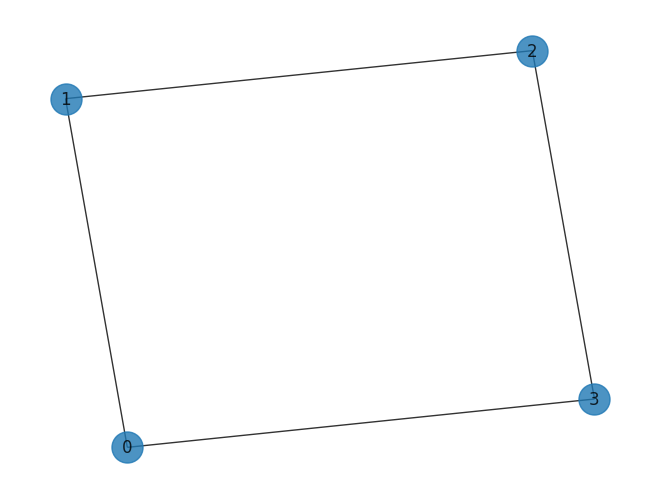

In [4]:
import networkx as nx
import matplotlib.pyplot as plt
import networkx as nx

G = nx.Graph()
G.add_nodes_from([0, 1, 2, 3])
G.add_edges_from([(0, 1), (1, 2), (2, 3), (3, 0)])
nx.draw(G, with_labels=True, alpha=0.8, node_size=500)

In [5]:
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit import Aer, execute
from qiskit.circuit import Parameter

# Adjacency is essentially a matrix which tells you which nodes are
# connected. This matrix is given as a sparse matrix, so we need to
# convert it to a dense matrix
adjacency = nx.adjacency_matrix(G).todense()

nqubits = 4

beta = Parameter("$\\beta$")
qc_mix = QuantumCircuit(nqubits)
for i in range(0, nqubits):
    qc_mix.rx(2 * beta, i)
    
qc_mix.draw()

/tmp/ipykernel_10202/3511420527.py:8: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  adjacency = nx.adjacency_matrix(G).todense()


┌───────────────┐
q_0: ┤ Rx(2*$\beta$) ├
     ├───────────────┤
q_1: ┤ Rx(2*$\beta$) ├
     ├───────────────┤
q_2: ┤ Rx(2*$\beta$) ├
     ├───────────────┤
q_3: ┤ Rx(2*$\beta$) ├
     └───────────────┘

In [6]:
gamma = Parameter("$\\gamma$")
qc_p = QuantumCircuit(nqubits)
for pair in list(G.edges()):  # pairs of nodes
    qc_p.rzz(2 * gamma, pair[0], pair[1])
    qc_p.barrier()
    
qc_p.decompose().draw()

░                              ░      »
q_0: ──■──────────────────────■───░───■──────────────────────■───░──────»
     ┌─┴─┐┌────────────────┐┌─┴─┐ ░   │                      │   ░      »
q_1: ┤ X ├┤ Rz(2*$\gamma$) ├┤ X ├─░───┼──────────────────────┼───░───■──»
     └───┘└────────────────┘└───┘ ░   │                      │   ░ ┌─┴─┐»
q_2: ─────────────────────────────░───┼──────────────────────┼───░─┤ X ├»
                                  ░ ┌─┴─┐┌────────────────┐┌─┴─┐ ░ └───┘»
q_3: ─────────────────────────────░─┤ X ├┤ Rz(2*$\gamma$) ├┤ X ├─░──────»
                                  ░ └───┘└────────────────┘└───┘ ░      »
«                             ░                              ░ 
«q_0: ────────────────────────░──────────────────────────────░─
«                             ░                              ░ 
«q_1: ────────────────────■───░──────────────────────────────░─
«     ┌────────────────┐┌─┴─┐ ░                              ░ 
«q_2: ┤ Rz(2*$\gamma$) ├┤ X ├─░───■──────────────────────■───░─
«     └────────────────┘└───┘ ░ ┌─┴─┐┌────────────────┐┌─┴─┐ ░ 
«q_3: ────────────────────────░─┤ X ├┤ Rz(2*$\gamma$) ├┤ X ├─░─
«                             ░ └───┘└────────────────┘└───┘ ░

In [7]:
qc_0 = QuantumCircuit(nqubits)
for i in range(0, nqubits):
    qc_0.h(i)
    
qc_0.draw()

┌───┐
q_0: ┤ H ├
     ├───┤
q_1: ┤ H ├
     ├───┤
q_2: ┤ H ├
     ├───┤
q_3: ┤ H ├
     └───┘

In [8]:
qc_qaoa = QuantumCircuit(nqubits)

qc_qaoa.append(qc_0, [i for i in range(0, nqubits)])
qc_qaoa.append(qc_p, [i for i in range(0, nqubits)])
qc_qaoa.append(qc_mix, [i for i in range(0, nqubits)])

qc_qaoa.decompose().decompose().draw()

┌─────────┐                             ░                              ░ »
q_0: ┤ U2(0,π) ├──■──────────────────────■───░───■──────────────────────■───░─»
     ├─────────┤┌─┴─┐┌────────────────┐┌─┴─┐ ░   │                      │   ░ »
q_1: ┤ U2(0,π) ├┤ X ├┤ Rz(2*$\gamma$) ├┤ X ├─░───┼──────────────────────┼───░─»
     ├─────────┤└───┘└────────────────┘└───┘ ░   │                      │   ░ »
q_2: ┤ U2(0,π) ├─────────────────────────────░───┼──────────────────────┼───░─»
     ├─────────┤                             ░ ┌─┴─┐┌────────────────┐┌─┴─┐ ░ »
q_3: ┤ U2(0,π) ├─────────────────────────────░─┤ X ├┤ Rz(2*$\gamma$) ├┤ X ├─░─»
     └─────────┘                             ░ └───┘└────────────────┘└───┘ ░ »
«                                  ░                              ░ »
«q_0: ─────────────────────────────░──────────────────────────────░─»
«                                  ░                              ░ »
«q_1: ──■──────────────────────■───░──────────────────────────────░─»
«     ┌─┴─┐┌────────────────┐┌─┴─┐ ░                              ░ »
«q_2: ┤ X ├┤ Rz(2*$\gamma$) ├┤ X ├─░───■──────────────────────■───░─»
«     └───┘└────────────────┘└───┘ ░ ┌─┴─┐┌────────────────┐┌─┴─┐ ░ »
«q_3: ─────────────────────────────░─┤ X ├┤ Rz(2*$\gamma$) ├┤ X ├─░─»
«                                  ░ └───┘└────────────────┘└───┘ ░ »
«     ┌────────────────┐
«q_0: ┤ R(2*$\beta$,0) ├
«     ├────────────────┤
«q_1: ┤ R(2*$\beta$,0) ├
«     ├────────────────┤
«q_2: ┤ R(2*$\beta$,0) ├
«     ├────────────────┤
«q_3: ┤ R(2*$\beta$,0) ├
«     └────────────────┘

In [9]:
def maxcut_obj(x, G):
    """
    Given a bitstring as a solution, this function returns
    the number of edges shared between the two partitions
    of the graph.
    
    Args:
        x: str
           solution bitstring
           
        G: networkx graph
        
    Returns:
        obj: float
             Objective
    """
    obj = 0
    for i, j in G.edges():
        if x[i] != x[j]:
            obj -= 1
            
    return obj


def compute_expectation(counts, G):
    
    """
    Computes expectation value based on measurement results
    
    Args:
        counts: dict
                key as bitstring, val as count
           
        G: networkx graph
        
    Returns:
        avg: float
             expectation value
    """
    
    avg = 0
    sum_count = 0
    for bitstring, count in counts.items():
        
        obj = maxcut_obj(bitstring[::-1], G)
        avg += obj * count
        sum_count += count
        
    return avg/sum_count


# We will also bring the different circuit components that
# build the qaoa circuit under a single function
def create_qaoa_circ(G, theta):
    
    """
    Creates a parametrized qaoa circuit
    
    Args:  
        G: networkx graph
        theta: list
               unitary parameters
                     
    Returns:
        qc: qiskit circuit
    """
    
    nqubits = len(G.nodes())
    p = len(theta)//2  # number of alternating unitaries
    qc = QuantumCircuit(nqubits)
    
    beta = theta[:p]
    gamma = theta[p:]
    
    # initial_state
    for i in range(0, nqubits):
        qc.h(i)
    
    for irep in range(0, p):
        
        # problem unitary
        for pair in list(G.edges()):
            qc.rzz(2 * gamma[irep], pair[0], pair[1])

        # mixer unitary
        for i in range(0, nqubits):
            qc.rx(2 * beta[irep], i)
            
    qc.measure_all()
        
    return qc

# Finally we write a function that executes the circuit on the chosen backend
def get_expectation(G, shots=512):
    
    """
    Runs parametrized circuit
    
    Args:
        G: networkx graph
        p: int,
           Number of repetitions of unitaries
    """
    
    backend = Aer.get_backend('qasm_simulator')
    backend.shots = shots
    
    def execute_circ(theta):
        
        qc = create_qaoa_circ(G, theta)
        counts = backend.run(qc, seed_simulator=10, 
                             nshots=512).result().get_counts()
        
        return compute_expectation(counts, G)
    
    return execute_circ

In [10]:
from scipy.optimize import minimize


expectation = get_expectation(G)

res = minimize(expectation, 
                      [1.0, 1.0], 
                      method='COBYLA')
res

     fun: -2.994140625
   maxcv: 0.0
 message: 'Optimization terminated successfully.'
    nfev: 30
  status: 1
 success: True
       x: array([1.9793337 , 1.16663483])

In [12]:
from qiskit.visualization import plot_histogram

backend = Aer.get_backend('aer_simulator')
backend.shots = 512

qc_res = create_qaoa_circ(G, res.x)

qc_res.draw()

┌───┐                          ┌────────────┐              »
   q_0: ┤ H ├─■────────────■───────────┤ Rx(3.9587) ├──────────────»
        ├───┤ │ZZ(2.3333)  │           └────────────┘┌────────────┐»
   q_1: ┤ H ├─■────────────┼────────────■────────────┤ Rx(3.9587) ├»
        ├───┤              │            │ZZ(2.3333)  └────────────┘»
   q_2: ┤ H ├──────────────┼────────────■─────────────■────────────»
        ├───┤              │ZZ(2.3333)                │ZZ(2.3333)  »
   q_3: ┤ H ├──────────────■──────────────────────────■────────────»
        └───┘                                                      »
meas_0: ═══════════════════════════════════════════════════════════»
                                                                   »
meas_1: ═══════════════════════════════════════════════════════════»
                                                                   »
meas_2: ═══════════════════════════════════════════════════════════»
                                                                   »
meas_3: ═══════════════════════════════════════════════════════════»
                                                                   »
«                       ░ ┌─┐         
«   q_0: ───────────────░─┤M├─────────
«                       ░ └╥┘┌─┐      
«   q_1: ───────────────░──╫─┤M├──────
«        ┌────────────┐ ░  ║ └╥┘┌─┐   
«   q_2: ┤ Rx(3.9587) ├─░──╫──╫─┤M├───
«        ├────────────┤ ░  ║  ║ └╥┘┌─┐
«   q_3: ┤ Rx(3.9587) ├─░──╫──╫──╫─┤M├
«        └────────────┘ ░  ║  ║  ║ └╥┘
«meas_0: ══════════════════╩══╬══╬══╬═
«                             ║  ║  ║ 
«meas_1: ═════════════════════╩══╬══╬═
«                                ║  ║ 
«meas_2: ════════════════════════╩══╬═
«                                   ║ 
«meas_3: ═══════════════════════════╩═
«

In [13]:
qc_res.remove_final_measurements(inplace=True)
special_circ = remove_gates(qc_res)

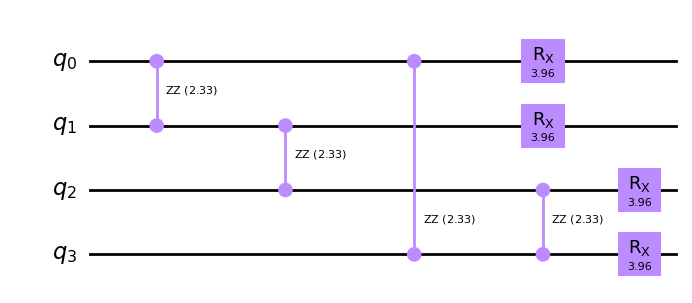

In [14]:
special_circ.draw(output="mpl")

In [43]:
write_gates_to_file(special_circ, 4, "../../data/other/qaoa_temp")

CircuitInstruction(operation=Instruction(name='rzz', num_qubits=2, num_clbits=0, params=[2.3332696592189612]), qubits=(Qubit(QuantumRegister(4, 'q'), 0), Qubit(QuantumRegister(4, 'q'), 1)), clbits=())
* 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 * 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 * 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 * 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 * 0 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 * 0 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 * 0 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 * 0 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 * 0 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 * 0 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 * 0 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 * 0 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 0 * 0 0 0 
0 0 0 0 0 0 0 0 0 0 0 0 0 * 0 0 
0 0 0 0 0 0 0 0 0 0 0 0 0 0 * 0 
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 * 
CircuitInstruction(operation=Instruction(name='rzz', num_qubits=2, num_clbits=0, params=[2.3332696592189612]), qubits=(Qubit(QuantumRegister(4, 'q'), 1), Qubit(QuantumRegister(4, 'q'), 2)), clbits=())
* 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 * 0 0 0 0 0 0 0 0 0 0 0 0 0 0 
0 0 

In [42]:
def matrix_print01(nparray):
    for x in nparray:
        for y in x:
            a = int(y.real != 0.0 or y.imag != 0.0)
#             print(y.real, y.imag, a)
            if a != 0:
                print(termcolor.colored("*", 'red') ,end=" ", sep="")
            else:
                print(a, end=" ", sep="")
        print()

In [34]:
unitary_backend = Aer.get_backend('unitary_simulator')
job = execute(special_circ, unitary_backend, shots=1024)
result = job.result()
d = result.get_unitary(special_circ, 3).data

In [39]:
matrix_print01(d)

-0.001 0.025 1
* -0.0 0.058 1
* 0.0 0.058 1
* -0.133 0.0 1
* 0.0 0.058 1
* 0.006 0.133 1
* -0.133 0.0 1
* 0.0 -0.307 1
* 0.0 0.058 1
* -0.133 0.0 1
* 0.006 0.133 1
* -0.0 -0.307 1
* -0.133 -0.0 1
* 0.0 -0.307 1
* 0.0 -0.307 1
* -0.033 0.709 1
* 
-0.057 -0.003 1
* 0.025 0.0 1
* -0.133 0.0 1
* 0.0 0.058 1
* -0.133 0.0 1
* 0.057 -0.003 1
* 0.0 -0.307 1
* -0.133 0.0 1
* -0.133 0.0 1
* 0.0 0.058 1
* -0.307 0.014 1
* -0.133 0.0 1
* 0.0 -0.307 1
* -0.133 -0.0 1
* 0.709 0.0 1
* 0.307 0.014 1
* 
-0.057 -0.003 1
* -0.133 0.0 1
* 0.025 0.0 1
* -0.0 0.058 1
* -0.133 0.0 1
* -0.307 0.014 1
* 0.0 0.058 1
* -0.133 0.0 1
* -0.133 0.0 1
* -0.0 -0.307 1
* 0.057 -0.003 1
* -0.133 0.0 1
* 0.0 -0.307 1
* 0.709 0.0 1
* -0.133 -0.0 1
* 0.307 0.014 1
* 
0.006 -0.133 1
* 0.0 0.058 1
* -0.0 0.058 1
* 0.025 0.0 1
* 0.0 -0.307 1
* 0.006 0.133 1
* -0.133 0.0 1
* 0.0 0.058 1
* -0.0 -0.307 1
* -0.133 0.0 1
* 0.006 0.133 1
* 0.0 0.058 1
* 0.709 0.0 1
* 0.0 -0.307 1
* 0.0 -0.307 1
* 0.006 -0.133 1
* 
-0.057 -0.003 1
*